<a href="https://colab.research.google.com/github/bhavya1101-cse/aiml-2026-iiith-ihub/blob/main/AIML_Module_2_Lab_3A_Manifold_Learning_Methods.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Module 2: Appreciating, Interpreting and Visualizing Data
## Lab 3A: Manifold Learning Methods

---



Today, we will be focussing on non-linear dimensionality reduction methods or **Manifold learning** methods.

So a manifold is any space that is locally Euclidean. For example, the Earth is round but it looks flat to us. The Earth is a manifold: locally it is flat, but globally we know it is a sphere. Then, manifold learning performs dimensionality reduction by representing data as low-dimensional manifolds embedded in a higher-dimensional space.

We often suspect that high-dim may actually lie on or near a low-dim manifold (often much lower!) and it would be useful if we could reparametrize the data in terms of this manifold, yielding a low-dim embedding BUT - we typically don’t know the form of this manifold.

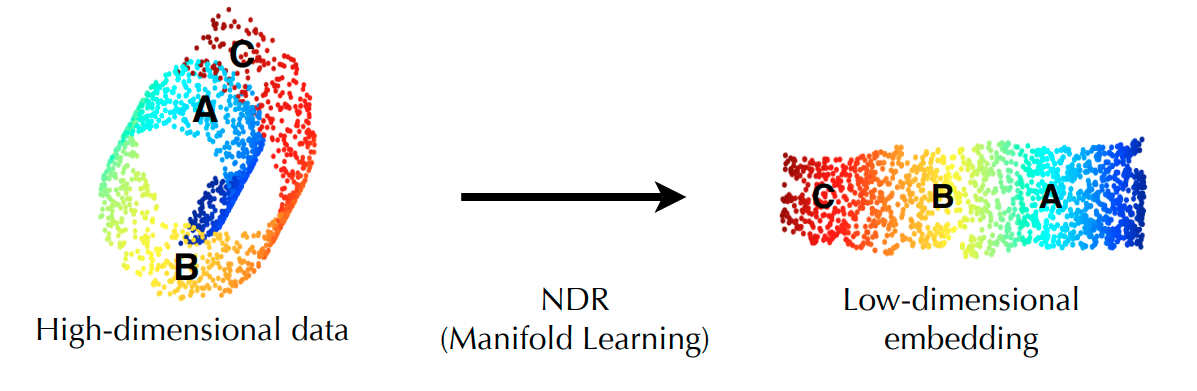

**What is a Manifold?**

**Analogy:**

Imagine you’re an ant walking on a globe. To you, the surface seems flat, but in reality, it’s curved. The globe is a manifold: locally flat, but globally curved. Manifold learning tries to "unroll" this globe into a flat map, preserving the true distances as much as possible.

**Why do we care?**

High-dimensional data (e.g., images, text, or sensor data) often lies on a lower-dimensional "surface" (manifold) embedded in a high-dimensional space.
Manifold learning helps us discover and visualize this hidden structure.

## ISOMAP

---

Isomap stands for **ISOmetric feature MAPping**. Isomap is a non-linear dimensionality reduction method based on the spectral theory which tries to preserve the geodesic distances in the lower dimension.

#### But what are Geodesic Distances?



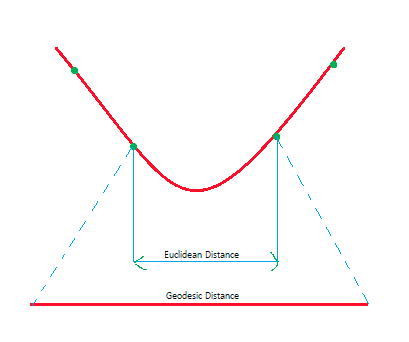

**Euclidean vs. Geodesic Distances:**

- Euclidean distance: Straight-line distance between two points.
- Geodesic distance: Shortest path along the surface of the manifold.

**Example:**

On Earth, the Euclidean distance between two cities is a straight line through the planet (useless!). The geodesic distance is the great-circle distance (what GPS uses).

The next question should be:

*How can we compute geodesics without knowing the manifold?* .......
ANSWER: So we build an adjacency graph and approximate geodesic distances by shortest-paths through the graph.


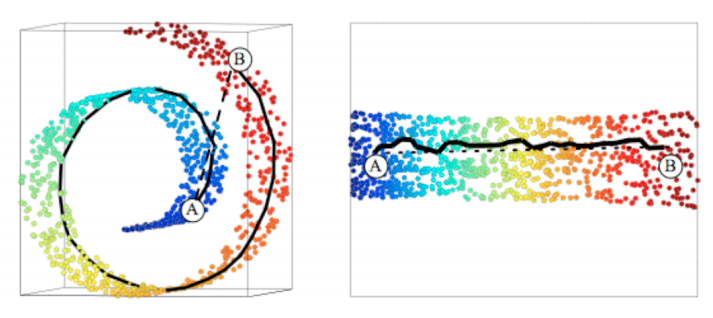

#### 3 steps for ISOMAP:

1. Build the adjacency graph over the points using a Neighbourhood selection method (let's say k nearest neighbours)
2. Compute approximate geodesics: Weight graph edges by inter-point distances and then apply Dijkstra’s all-pairs shortest-paths algorithm.
3. Take the top d eigenvectors of the Gram matrix.


**What is Isomap?**

Isomap is like a GPS for data points. Instead of using straight-line (Euclidean) distances, it uses "road distances" (geodesic distances) to map the data.
It’s useful when data points are connected in a non-linear way (e.g., a curved surface).

**Example:**

Think of a piece of paper rolled into a tube. If you measure distances along the paper (not through the air), you’re using geodesic distances. Isomap tries to "flatten" the tube while keeping these distances accurate.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn import datasets

First let us simulate a dataset with the points lying on a manifold which we would want our Isomap to be able to capture.

We will be using the make_s_curve() function in the sklearn.datasets module to make the manifold using 1000 data points

In [ ]:
n_points = 1000
X, color = datasets.make_s_curve(n_points, random_state=0)

**Why use the S-curve?**

The S-curve is a classic example of a 2D manifold embedded in 3D space.
It’s non-linear, so linear methods like PCA struggle to "unroll" it, but Isomap can.

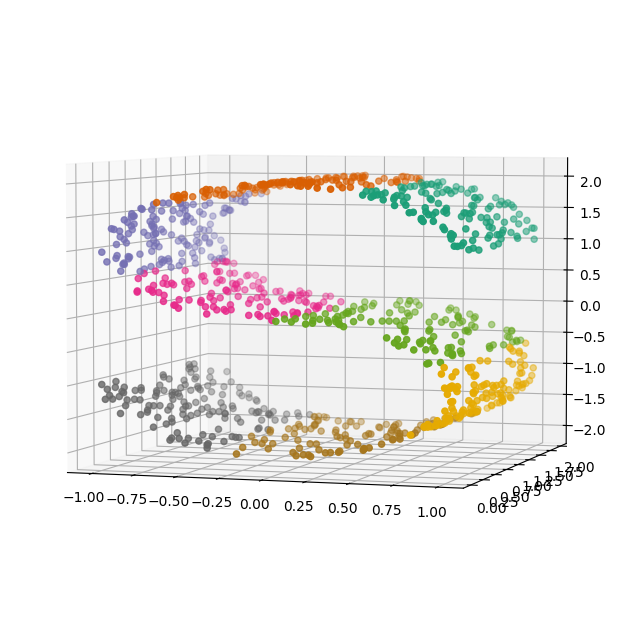

In [ ]:
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')
ax.scatter(X[:, 0], X[:, 1], X[:, 2], c=color, cmap=plt.cm.Dark2)
ax.view_init(4, -72)

**Observation:**

- The S-curve is a 2D surface (a sheet of paper) bent in 3D space.
- Isomap will try to "unbend" this surface into a flat 2D plane.

Note that all the points appear to be a lying on a curved 2d plane in this 3d dataset. Now we will be coding the Isomap algorithm to perform this manifold learning.


---

### Step 1a: First lets compute the distance matrix (pairwise Euclidean distances) from the data


In [ ]:
def dist(a, b):
  '''Computes Euclidean distance between 2 points'''
  return np.sqrt(sum((a - b) ** 2))

distances = np.array([[dist(p1, p2) for p2 in X] for p1 in X])

# For N points in the dataset, this matrix should be of the dimension NxN.
# Our dataset had 1000 points, so we expect the dimensions of this matrix to be 1000x1000
print(distances.shape)

(1000, 1000)


**What’s happening?**

- We compute the Euclidean distance between every pair of points.
- This gives us an N x N matrix, where N is the number of points (1000 here).

### Step 1b: Let us keep only k nearest neighbors for each point in the distance matrix.

In [ ]:
# Lets keep only the 10 nearest neighbors, others set to 0 (= unreachable)

n_neighbors = 10
neighbors = np.zeros(distances.shape)

sort_distances = np.argsort(distances, axis=1)[:, 1:n_neighbors+1]
for k,i in enumerate(sort_distances):
    neighbors[k,i] = distances[k,i]

In [ ]:
neighbors.shape

(1000, 1000)

**Adjacency Graph**

**What’s happening?**

- We connect each point to its k nearest neighbors, creating a network (graph).
- This graph approximates the true shape of the manifold.

**Analogy:**

Imagine you’re in a maze. You can only see nearby walls (neighbors). By connecting to your neighbors, you can find the shortest path to any other point in the maze.



---

### Step 2: Weight graph edges by inter-point distances and then apply Dijkstra’s all-pairs shortest-paths algorithm.

We will be using the graph_shortest_path() function in the sklearn.utils.graph module.

The function takes an array of positive distances as the parameter. It then performs a shortest-path graph search on the graph and returns a matrix G (shape = N,N), where, G(i,j) gives the shortest distance from point i to point j along the graph.


In [ ]:
from scipy.sparse.csgraph import shortest_path

graph = shortest_path(neighbors, directed=False)

**Dijkstra’s Algorithm**

**What’s happening?**

- We calculate the shortest path between every pair of points using Dijkstra’s algorithm.
- This gives us the "true" distances along the manifold, not just straight-line distances.

**Example:**

If you’re driving from Delhi to Mumbai, the road distance (geodesic) is longer than the straight-line (Euclidean) distance on a map. Isomap uses the road distance.



---
### Step 3: Take the top d eigenvectors of the Gram matrix.


So let us first compute the gram matrix. If we have a matrix **graph**, then its Gram matrix is **graph**.T * **graph**





In [ ]:
gram = (graph ** 2)

We will now be computing the eigenvectors for this matrix, so lets first center the data points.

In [ ]:
n_samples = gram.shape[0]

# Mean for each row/column
meanrows = np.sum(gram, axis=0) / n_samples
meancols = (np.sum(gram, axis=1)/n_samples)[:, np.newaxis]

# NUMPY TRICKS: np.newaxis is used to increase the dimension of the existing array by one more dimension. So a (1000,) matrix becomes a (1000,1) matrix.

# Mean across all rows (entire matrix)
meanall = meanrows.sum() / n_samples

gram -= meanrows
gram -= meancols
gram += meanall

Computing eigenvectors

In [ ]:
# Using the np.linalg.eig() to compute eigenvectors and eigenvalues for the matrix
eig_val_cov, eig_vec_cov = np.linalg.eig(gram)

# We will be sorting the eigenvalues and to preserve the corresponding eigenvectors, let us make a list of (eigenvalue, eigenvector) tuples
eig_pairs = [(np.abs(eig_val_cov[i]), eig_vec_cov[:, i]) for i in range(len(eig_val_cov))]

# We want to reduce the dimensionality to **n_components** dimensions, therefore we will be first taking the top **n_components** eigenvectors (sorted in descending by eigenvalues)
eig_pairs.sort(key=lambda x: x[0], reverse=True)
eig_pa_chebyshevirs = np.array(eig_pairs, dtype=object)

# Transforming the matrix (dimensionality reduction)
n_components = 2

reduced_matrix = np.zeros((n_components, gram.shape[1]))
for i in range(n_components):
  reduced_matrix[i,:] = eig_pa_chebyshevirs[i,1]
reduced_matrix = reduced_matrix.T

**Eigenvectors and the Gram Matrix**

**What’s happening?**

- We compute the Gram matrix (a matrix of inner products) and find its top eigenvectors.
- These eigenvectors give us the coordinates in the lower-dimensional space.

**Analogy:**

Think of the Gram matrix as a "distortion detector." The top eigenvectors help us "unfold" the manifold into a flat space.



---

## Plotting the resultant reduced_matrix


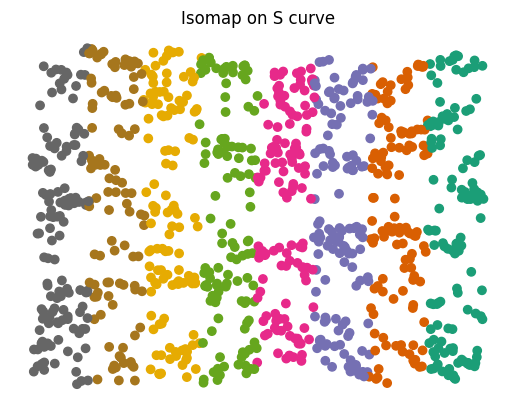

In [ ]:
ax = fig.add_subplot(111)
plt.scatter(reduced_matrix[:, 0], reduced_matrix[:, 1], c=color, cmap=plt.cm.Dark2)
plt.title("Isomap on S curve")
plt.axis('off')
plt.show()

**Isomap on the S-Curve**

**What’s happening in the code?**

- We generate a 3D S-shaped curve.
- We compute pairwise distances and keep only the k nearest neighbors.
- We use Dijkstra’s algorithm to find the shortest paths (geodesics).
- We reduce the data to 2D using eigenvectors.

**Visualization:**

The 3D S-curve is "unrolled" into a 2D plane, preserving the structure.

##### As you can see the Isomap was able to capture the underlying 2d manifold in the S curve dataset.

Now of course there is an easier way to do this, using a predefined library Isomap by sklearn in the manifold module. It just requires you to enter the number of neighbours to be considered and the number of components the graph is to be reduced to.


In [ ]:
from sklearn.manifold import Isomap

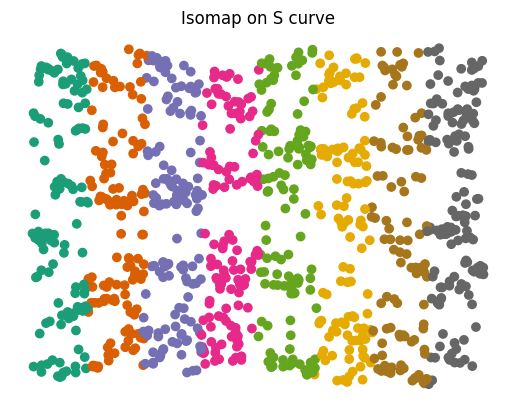

In [ ]:
Y = Isomap(n_neighbors=10, n_components=2).fit_transform(X)

ax = fig.add_subplot(111)
plt.scatter(Y[:, 0], Y[:, 1], c=color, cmap=plt.cm.Dark2)
plt.title("Isomap on S curve")
plt.axis('off')
plt.show()

**Why Use sklearn?**
**Why use sklearn's Isomap?**

- The manual implementation helps you understand the math, but sklearn is optimized and easier to use.
- It’s also more robust for real-world datasets.



---

### Now let us see if Isomap can learn the manifold representation in some more complex datasets

In [ ]:
from sklearn.datasets import fetch_lfw_people
faces = fetch_lfw_people(min_faces_per_person=200)
faces.data.shape

(766, 2914)

We loaded 766 images, each having 2914 pixels. Let us visualize our dataset before reducing the dimension

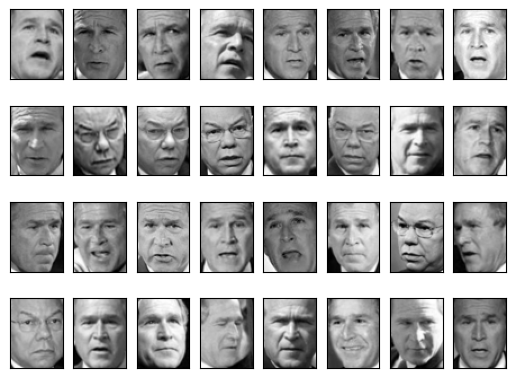

In [ ]:
fig, ax = plt.subplots(4, 8, subplot_kw=dict(xticks=[], yticks=[]))
for i, axi in enumerate(ax.flat):
    axi.imshow(faces.images[i], cmap='gray')

**Why Faces?**
**Why use Isomap on faces? **

- Faces are high-dimensional (2914 pixels), but the meaningful variations (e.g., orientation, lighting) lie on a lower-dimensional manifold.
- Isomap reveals these hidden structures.

Our data is 2914 dimensional and our goal is to learn a low dimensional manifold from it. We first apply PCA (which we learn in Lab 2) and see if PCA is able to reduce it to lower dimensions while preserving much of the variance.

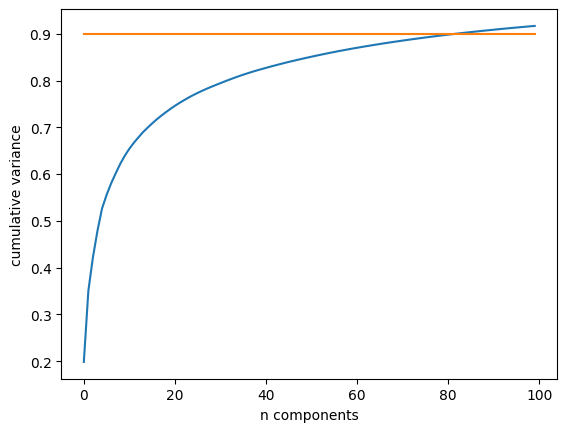

In [ ]:
from sklearn.decomposition import PCA as RandomizedPCA
model = RandomizedPCA(100).fit(faces.data)
plt.plot(np.cumsum(model.explained_variance_ratio_))
plt.xlabel('n components')
plt.ylabel('cumulative variance')
plt.plot(range(100), 0.9*np.ones(100))

Let us now try to apply Isomap to this dataset and see if it is able to learn the representation effectively.

In [ ]:
model = Isomap(n_components=2, n_neighbors = 5)
proj = model.fit_transform(faces.data)
proj.shape

(766, 2)

We have reduced the dataset from 2914 dimensions to just 2 dimensions. Let us now visualize the result to be able to better understand the latent representation learnt by Isomap

In [ ]:
from matplotlib import offsetbox

def plot_components(data, model, images=None, ax=None, thumb_frac=0.05, cmap='gray'):

    ax = ax or plt.gca()
    proj = model.fit_transform(data)
    ax.plot(proj[:, 0], proj[:, 1], '.k')

    if images is not None:
        min_dist_2 = (thumb_frac * max(proj.max(0) - proj.min(0))) ** 2
        shown_images = np.array([2 * proj.max(0)])
        for i in range(data.shape[0]):
            dist = np.sum((proj[i] - shown_images) ** 2, 1)
            if np.min(dist) < min_dist_2:
                # don't show points that are too close
                continue
            shown_images = np.vstack([shown_images, proj[i]])
            imagebox = offsetbox.AnnotationBbox(
                offsetbox.OffsetImage(images[i], cmap=cmap),
                                      proj[i])
            ax.add_artist(imagebox)

Text(0, 0.5, 'Image Darkness')

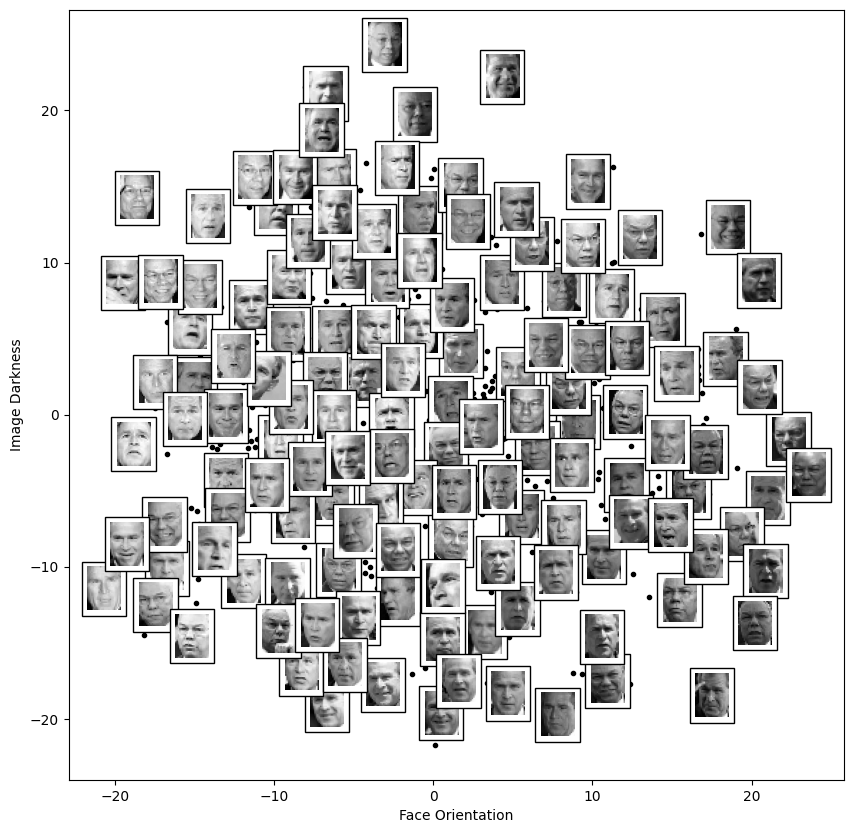

In [ ]:
fig, ax = plt.subplots(figsize=(10, 10))
plot_components(faces.data,
                model=Isomap(n_components=2, n_neighbors = 5),
                images=faces.images[:, ::2, ::2])
plt.xlabel("Face Orientation")
plt.ylabel("Image Darkness")

**PCA vs. Isomap on Faces**

**Observation:**

- PCA needs 70+ dimensions to explain 90% of the variance, implying that PCA is failing to learn the underlying manifold effectively.
- Isomap reduces the data to 2D while preserving meaningful structure (orientation and darkness).

**Interpreting the Face Plot**

**Observation:**

- The 2D plot shows faces arranged by orientation (left to right) and darkness (bottom to top).
- This means Isomap discovered two key features without being told what to look for!

**Example:**

If you sort photos of a person’s face from bright to dark and left-profile to right-profile, you’re doing what Isomap does automatically.



**You are motivated to play around with the number of neighbors and check if the following holds true across neighbourhoods!**

---


# Exercises!!

1. How do you think would the number of neighbors effect the Isomap algorithm? What happens when the number of neighbors considered is very large? What happens when it is very low?

2. When is the ISOMAP algorithm superior to PCA?

3. Search up another manifold learning methods other than ISOMAP? If there are any, whats the key difference ?

4. Suggest ways to deal with missing data in manifold learning.


---

# Answers to Exercies

### Setup for the answers

The cells below use the same S-curve dataset from the start of this lab (1000 points). To check how well a method **unrolls** the S-curve, I use a simple score:

- Every point on the S-curve has a true 2D position on the flat sheet: its position along the curve (`color`) and its height (`y`).
- After reducing to 2D, I check how well a straight-line (linear regression) fit can recover that true position from the 2D output. This is the **unrolling score** (R²).
- A score near **1.0** means the sheet was flattened correctly. A score near **0.5** means the structure got mixed up.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import warnings
from sklearn import datasets
from sklearn.manifold import Isomap
from sklearn.linear_model import LinearRegression
from scipy.sparse.csgraph import connected_components
from sklearn.neighbors import kneighbors_graph

warnings.filterwarnings("ignore")   # hide sklearn's "graph is not connected" warnings

# Same S-curve as the start of the lab
X_s, color_s = datasets.make_s_curve(1000, random_state=0)
true_2d = np.c_[color_s, X_s[:, 1]]   # true position on the flat sheet: (along the curve, height)

def unroll_score(Y, target=true_2d):
    """R^2 of recovering the true 2D sheet position from the embedding (1.0 = perfect unrolling)."""
    return LinearRegression().fit(Y, target).score(Y, target)

---
### Exercise 1
**How do you think would the number of neighbors effect the Isomap algorithm? What happens when the number of neighbors considered is very large? What happens when it is very low?**

Experiment: run Isomap on the S-curve with different numbers of neighbours (k) and compare.

k =   3 | separate graph pieces =  7 | unrolling score = 0.504


k =   5 | separate graph pieces =  1 | unrolling score = 0.963


k =  10 | separate graph pieces =  1 | unrolling score = 0.994


k =  30 | separate graph pieces =  1 | unrolling score = 0.999


k = 100 | separate graph pieces =  1 | unrolling score = 0.507


k = 300 | separate graph pieces =  1 | unrolling score = 0.458


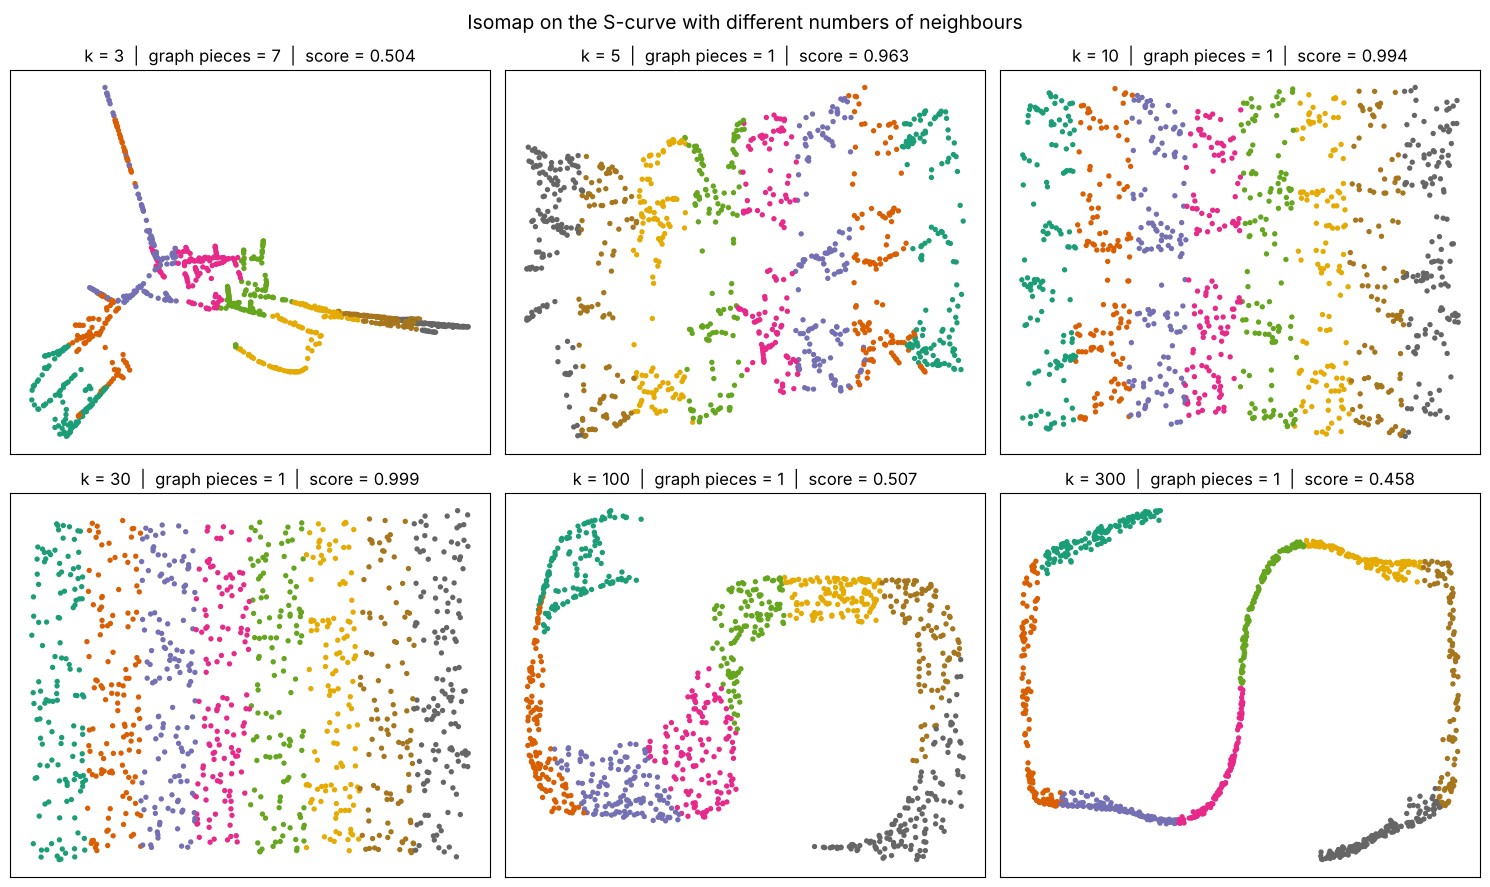

In [ ]:
k_values = [3, 5, 10, 30, 100, 300]
fig, axes = plt.subplots(2, 3, figsize=(15, 9))

for ax, k in zip(axes.flat, k_values):
    n_groups = connected_components(kneighbors_graph(X_s, k), directed=False)[0]
    Y_k = Isomap(n_neighbors=k, n_components=2).fit_transform(X_s)
    score = unroll_score(Y_k)
    ax.scatter(Y_k[:, 0], Y_k[:, 1], c=color_s, cmap=plt.cm.Dark2, s=8)
    ax.set_title(f"k = {k}  |  graph pieces = {n_groups}  |  score = {score:.3f}")
    ax.set_xticks([]); ax.set_yticks([])
    print(f"k = {k:>3} | separate graph pieces = {n_groups:>2} | unrolling score = {score:.3f}")

plt.suptitle("Isomap on the S-curve with different numbers of neighbours", fontsize=14)
plt.tight_layout()
plt.show()

**Answer:**

The number of neighbours (k) decides which points are connected in the graph, and Isomap measures every distance by walking along that graph. So k controls how well the graph follows the true shape of the manifold.

| k | Graph pieces | Unrolling score | What happened |
|---|---|---|---|
| 3 | 7 | 0.504 | Graph breaks into separate pieces |
| 5 | 1 | 0.963 | Good |
| 10 | 1 | 0.994 | Very good |
| 30 | 1 | 0.999 | Best |
| 100 | 1 | 0.507 | Shortcuts, S-curve not unrolled |
| 300 | 1 | 0.458 | Behaves like straight-line distance |

- **Very low k (e.g. 3):** each point connects to only a few nearby points, so the graph splits into **separate disconnected pieces** (7 pieces for k = 3). Points in different pieces have no path between them, so their geodesic distance is infinite or undefined, and Isomap cannot place the pieces correctly relative to each other. The result is a broken, distorted map (score 0.504). Small k is also very sensitive to noise, since one bad neighbour can change many shortest paths.
- **Very large k (e.g. 100 or 300):** points get connected to other points that are close in 3D space but far apart **along the surface**, for example across the gap between two bends of the "S". These edges act as **shortcuts**, so the shortest path no longer follows the surface. Geodesic distances turn back into ordinary straight-line (Euclidean) distances, and Isomap behaves almost like PCA. It fails to unroll the S-curve (scores 0.507 and 0.458, close to PCA's 0.471 in Exercise 2). It's also slower, because the graph has many more edges.
- **Moderate k (5 to 30 here):** the graph is connected, but each point only links to points that are truly near it on the surface. The S-curve unrolls into a clean flat rectangle (scores 0.96 to 0.999).

So k has to be **large enough to keep the graph connected, but small enough to avoid shortcuts** across the manifold. The best value depends on how dense and how noisy the data is, and there's no exact formula for it, so in practice we try a few values and look at the results, as done here.

---
### Exercise 2
**When is the ISOMAP algorithm superior to PCA?**

Experiment: PCA vs Isomap on the same S-curve.

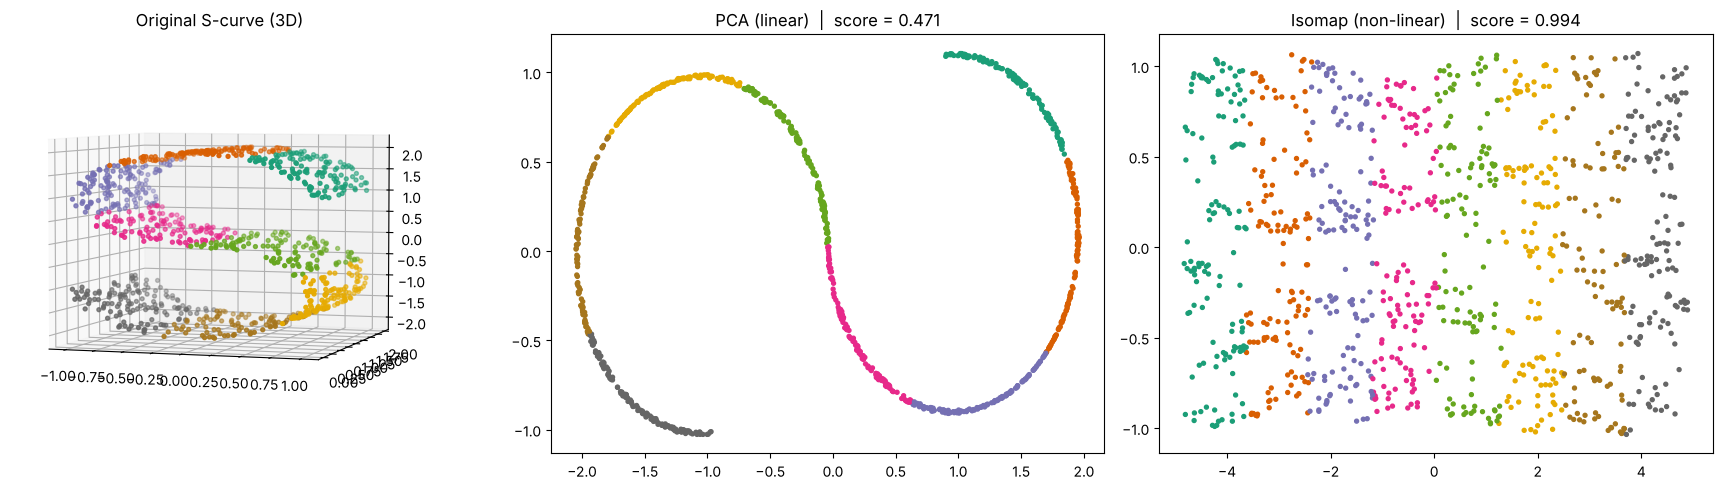

PCA    unrolling score: 0.471
Isomap unrolling score: 0.994


In [ ]:
from sklearn.decomposition import PCA

Y_pca = PCA(n_components=2).fit_transform(X_s)
Y_iso = Isomap(n_neighbors=10, n_components=2).fit_transform(X_s)

fig = plt.figure(figsize=(18, 5))
ax = fig.add_subplot(131, projection='3d')
ax.scatter(X_s[:, 0], X_s[:, 1], X_s[:, 2], c=color_s, cmap=plt.cm.Dark2, s=8)
ax.view_init(4, -72); ax.set_title("Original S-curve (3D)")

ax = fig.add_subplot(132)
ax.scatter(Y_pca[:, 0], Y_pca[:, 1], c=color_s, cmap=plt.cm.Dark2, s=8)
ax.set_title(f"PCA (linear)  |  score = {unroll_score(Y_pca):.3f}")

ax = fig.add_subplot(133)
ax.scatter(Y_iso[:, 0], Y_iso[:, 1], c=color_s, cmap=plt.cm.Dark2, s=8)
ax.set_title(f"Isomap (non-linear)  |  score = {unroll_score(Y_iso):.3f}")

plt.tight_layout()
plt.show()

print(f"PCA    unrolling score: {unroll_score(Y_pca):.3f}")
print(f"Isomap unrolling score: {unroll_score(Y_iso):.3f}")

**Answer:**

PCA can only **rotate and flatten** the data along straight directions. It squashes the S-curve flat, like pressing a curled sheet of paper onto a table, so points from different bends of the "S" land on top of each other (unrolling score **0.471**). Isomap measures distance **along the surface** and **unrolls** the sheet into a clean rectangle where the colours run in order (score **0.994**).

Isomap is superior to PCA when:

1. **The data lies on a curved (non-linear) surface**, like the S-curve, a Swiss roll, or face images that change smoothly with head angle and lighting. PCA assumes a flat structure and mixes up points that are far apart along the curve.
2. **The distance along the surface matters more than the straight-line distance.** Two points on opposite bends of the S are close in 3D but far apart on the sheet. Isomap keeps them apart, PCA doesn't.
3. **We want very few dimensions for visualisation.** On the faces dataset, PCA needed about 70+ components to keep 90% of the variance, while Isomap found a meaningful 2D picture (face orientation and darkness).
4. **The data is clean and dense enough** to build a good neighbour graph.

PCA is still better when the data is roughly linear, very large (Isomap is O(N²)–O(N³)), noisy, or has missing values, and when we need components with a clear meaning or a principled way (explained variance) to choose the number of dimensions. A common practice is to try **PCA first, then Isomap** if PCA can't reveal the structure.

---
### Exercise 3
**Search up another manifold learning methods other than ISOMAP? If there are any, whats the key difference ?**

Experiment: compare several manifold learning methods available in `sklearn.manifold` on the same S-curve.

PCA (linear, for reference)              unrolling score = 0.471   time = 0.0 s


Isomap                                   unrolling score = 0.994   time = 0.2 s
LLE                                      unrolling score = 0.668   time = 0.1 s
Laplacian Eigenmaps (SpectralEmbedding)  unrolling score = 0.489   time = 0.0 s


MDS                                      unrolling score = 0.465   time = 1.4 s


t-SNE                                    unrolling score = 0.985   time = 4.6 s


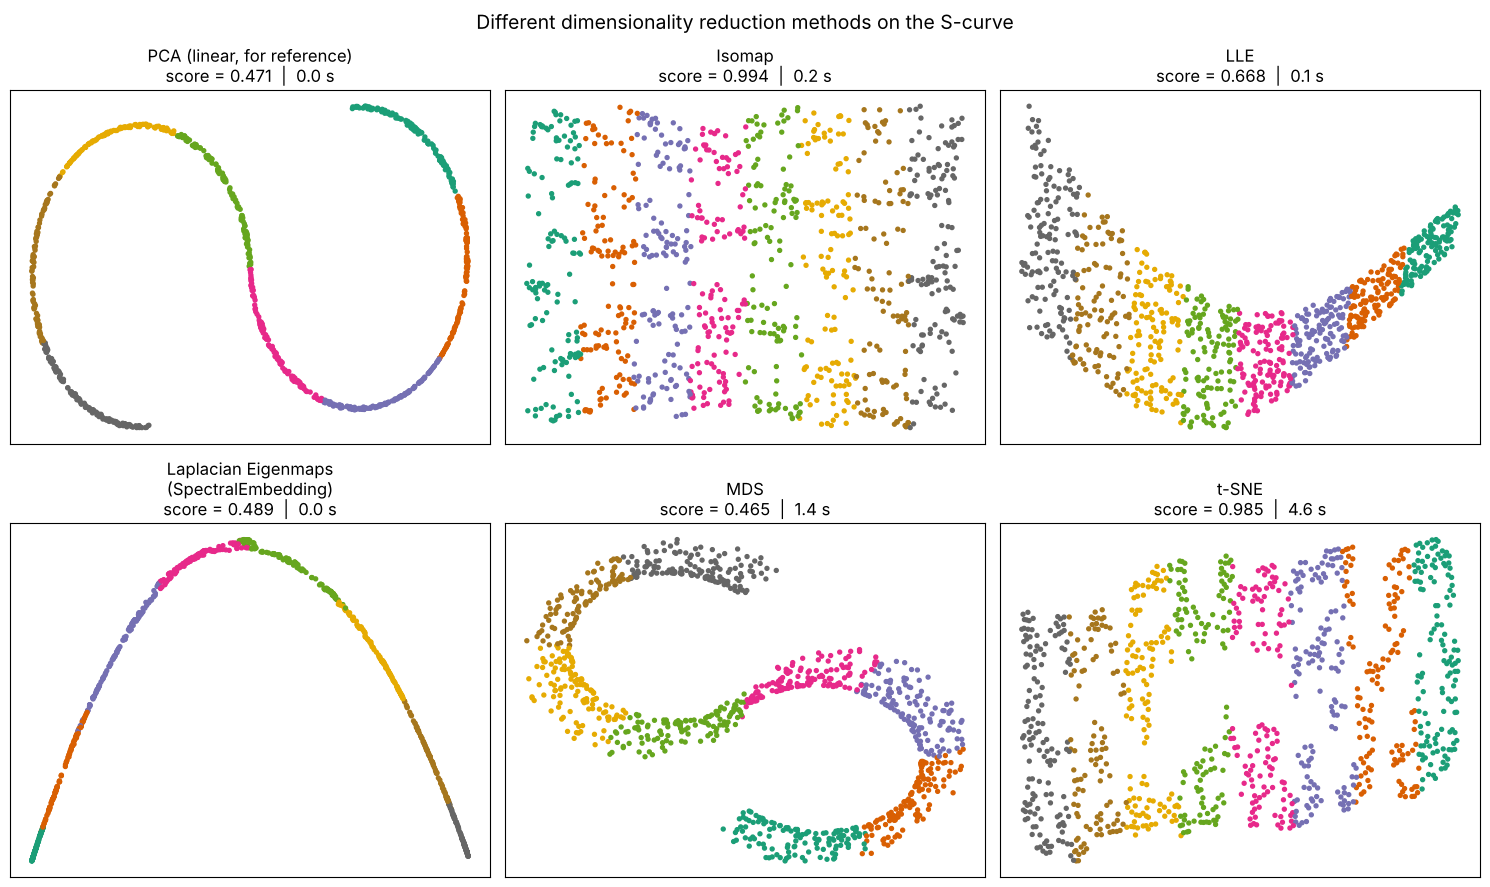

In [ ]:
from sklearn.manifold import LocallyLinearEmbedding, SpectralEmbedding, MDS, TSNE
import time

methods = {
    "PCA (linear, for reference)": PCA(n_components=2),
    "Isomap": Isomap(n_neighbors=10, n_components=2),
    "LLE": LocallyLinearEmbedding(n_neighbors=10, n_components=2, random_state=0),
    "Laplacian Eigenmaps\n(SpectralEmbedding)": SpectralEmbedding(n_components=2, n_neighbors=10, random_state=0),
    "MDS": MDS(n_components=2, random_state=0),
    "t-SNE": TSNE(n_components=2, random_state=0),
}

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, (name, method) in zip(axes.flat, methods.items()):
    start = time.time()
    Y_m = method.fit_transform(X_s)
    secs = time.time() - start
    ax.scatter(Y_m[:, 0], Y_m[:, 1], c=color_s, cmap=plt.cm.Dark2, s=8)
    ax.set_title(f"{name}\nscore = {unroll_score(Y_m):.3f}  |  {secs:.1f} s")
    ax.set_xticks([]); ax.set_yticks([])
    print(f"{name.replace(chr(10), ' '):<40} unrolling score = {unroll_score(Y_m):.3f}   time = {secs:.1f} s")

plt.suptitle("Different dimensionality reduction methods on the S-curve", fontsize=14)
plt.tight_layout()
plt.show()

**Answer:**

Yes, there are several other manifold learning methods. All of them try to find a low-dimensional picture of high-dimensional data, but they differ in **what they try to preserve**:

| Method | Main idea | Key difference from Isomap |
|---|---|---|
| **Isomap** | Keeps **geodesic distances** (shortest paths through the neighbour graph) between **all** pairs of points | Global method: tries to keep both near and far distances correct |
| **LLE (Locally Linear Embedding)** | Each point is rebuilt as a weighted mix of its neighbours. LLE finds a 2D layout where the same weights still work | **Local** method: only cares about each small neighbourhood and doesn't compute far-away distances. Faster, but can squash or distort the overall shape |
| **Laplacian Eigenmaps (Spectral Embedding)** | Builds a neighbour graph and places connected points close together, using eigenvectors of the graph Laplacian | Also **local**: keeps neighbours together, but doesn't try to keep exact distances |
| **MDS (Multidimensional Scaling)** | Keeps the **pairwise distances** as close as possible in low dimensions | Classical MDS uses ordinary **straight-line** distances. Isomap is MDS applied to **geodesic** distances instead |
| **t-SNE** | Converts distances to "probabilities of being neighbours" and matches them in 2D | Excellent for **visualising clusters**, but distances between far-apart clusters are not meaningful, it's random (results change between runs), and it's slow on large data |
| **UMAP** (`umap-learn` package) | Similar idea to t-SNE, based on a fuzzy neighbour graph | Faster than t-SNE and keeps more of the global structure. Widely used today |

In my experiment on the S-curve (unrolling score, where 1.0 is perfect):

- **Isomap: 0.994** and **t-SNE: 0.985** unrolled the sheet well.
- **LLE: 0.668**. It kept the colour order but squeezed the rectangle into a curved, uneven shape, because it only preserves local structure.
- **Laplacian Eigenmaps: 0.489**. The colours stay in the right order, but the whole sheet collapsed into a thin curved line, so the height direction of the sheet was lost. It keeps neighbours together, not distances.
- **MDS: 0.465** and **PCA: 0.471** failed, because both use straight-line distances, which take shortcuts across the bends of the S.

The **key difference** between methods is local vs global: Isomap and MDS try to preserve distances between *all* points, while LLE, Laplacian Eigenmaps, t-SNE and UMAP mainly preserve *neighbourhoods*. Isomap's specific trick is replacing straight-line distances with distances measured along the manifold.

---
### Exercise 4
**Suggest ways to deal with missing data in manifold learning.**

Experiment: hide 10% of the values in the S-curve at random, then compare different ways of handling them before running Isomap.

Rows with at least one missing value: 290 out of 1000


Drop incomplete rows   points used =  710   unrolling score = 0.992
Mean imputation        points used = 1000   unrolling score = 0.510
KNN imputation         points used = 1000   unrolling score = 0.418


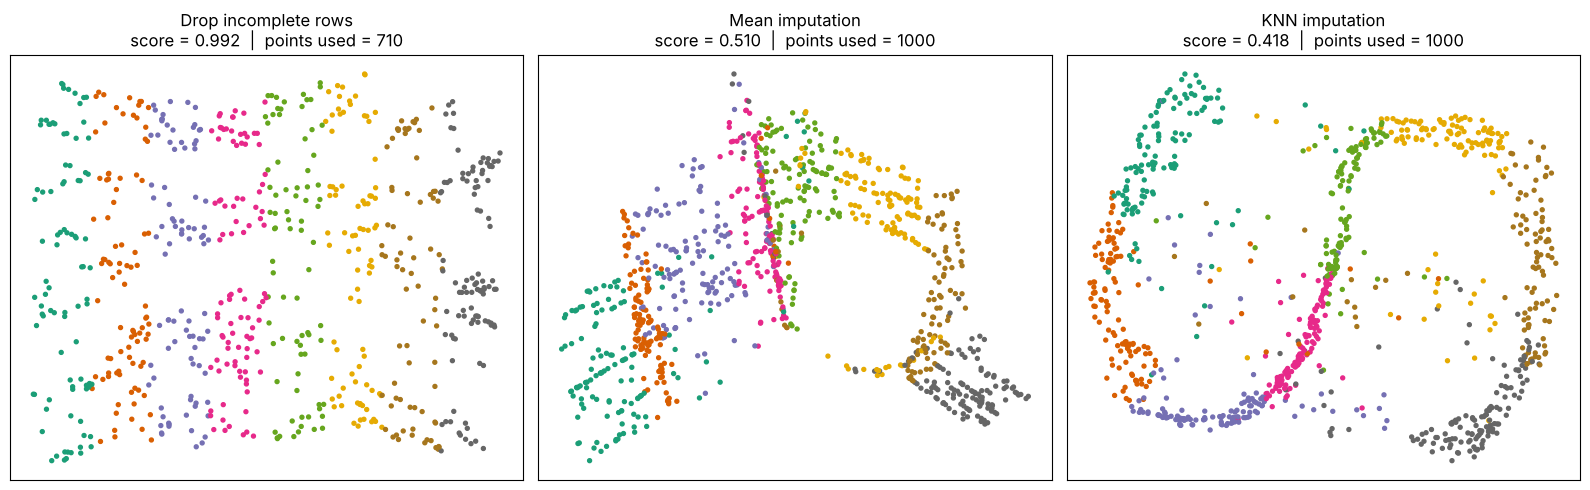

In [ ]:
from sklearn.impute import SimpleImputer, KNNImputer

rng = np.random.default_rng(0)
X_missing = X_s.copy()
X_missing[rng.random(X_s.shape) < 0.10] = np.nan          # hide 10% of all values
complete_rows = ~np.isnan(X_missing).any(axis=1)
print("Rows with at least one missing value:", (~complete_rows).sum(), "out of", len(X_s))

results = {}

# Option 1: drop rows that have any missing value
Y_drop = Isomap(n_neighbors=10, n_components=2).fit_transform(X_missing[complete_rows])
results["Drop incomplete rows"] = (Y_drop, color_s[complete_rows], unroll_score(Y_drop, true_2d[complete_rows]))

# Option 2: fill missing values with the column mean
Y_mean = Isomap(n_neighbors=10, n_components=2).fit_transform(SimpleImputer(strategy="mean").fit_transform(X_missing))
results["Mean imputation"] = (Y_mean, color_s, unroll_score(Y_mean))

# Option 3: fill missing values using the 5 most similar rows (KNN imputation)
Y_knn = Isomap(n_neighbors=10, n_components=2).fit_transform(KNNImputer(n_neighbors=5).fit_transform(X_missing))
results["KNN imputation"] = (Y_knn, color_s, unroll_score(Y_knn))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (name, (Y_r, c_r, score)) in zip(axes, results.items()):
    ax.scatter(Y_r[:, 0], Y_r[:, 1], c=c_r, cmap=plt.cm.Dark2, s=8)
    ax.set_title(f"{name}\nscore = {score:.3f}  |  points used = {len(Y_r)}")
    ax.set_xticks([]); ax.set_yticks([])
    print(f"{name:<22} points used = {len(Y_r):>4}   unrolling score = {score:.3f}")
plt.tight_layout()
plt.show()

**Answer:**

Manifold methods like Isomap need the distance between every pair of points, and that distance can't be calculated if a value is missing. Here are ways to deal with it:

1. **Drop incomplete rows (listwise deletion).** Remove any data point with a missing value. This is simple and safe when only a few rows are affected and plenty of data remains. In my experiment, 10% missing values affected 290 of the 1000 rows, but the remaining 710 points still unrolled almost perfectly (**score 0.992**). The downside is losing data, and the result can be biased if the missing values aren't random.
2. **Simple imputation (mean/median).** Fill each gap with the column's average. This is easy, but the filled-in points land **off the manifold**, and in my experiment they acted as false bridges between bends of the S, breaking the unrolling (**score 0.510**).
3. **KNN imputation.** Fill each gap using the most similar complete points. This usually beats the mean, but here it also failed (**score 0.418**) because the S-curve has only 3 features. When one of the 3 is missing, the other two aren't enough to find the true neighbours, so the guesses are often wrong. KNN imputation works much better on data with many correlated features, like images or sensor readings.
4. **Compute distances using only the available features.** Calculate the distance between two points on the features both of them have, and scale it up to make up for the missing ones (sometimes called a "partial distance"). The neighbour graph can then be built without filling in any values.
5. **Impute with PCA or matrix completion first.** Use iterative PCA, or `IterativeImputer` in sklearn, to estimate the missing values from the overall structure, then run the manifold method on the completed data.
6. **Fit on complete data, then add the rest later.** Learn the manifold using only complete rows, then place incomplete points onto it by comparing them with their nearest complete neighbours on the features they do have (an "out-of-sample" extension).
7. **Use methods robust to gaps.** Some newer approaches, such as autoencoders trained with masked inputs, handle missing values naturally.

**Lesson from the experiment:** in manifold learning, a badly filled-in value is worse than a missing one, because a single wrong point can create a shortcut that changes the whole geodesic distance graph. That's why the lab's conclusion says manifold learning has no good framework for missing data. If only a small fraction of rows is affected, **dropping them is often the safest choice**, and imputation should be checked carefully, e.g. by plotting the result, as done above.

**Challenges of Manifold Learning**

**Key Issues:**

- Noisy data can create "shortcuts" and distort the manifold.
- Choosing k (number of neighbors) is tricky. Too small → fragmented manifold; too large → loses local structure.
- Missing data is harder to handle than in PCA.

**Analogy:**

- If your GPS has bad signal (noisy data), it might suggest a wrong route.
- If you only ask 2 people for directions (k=2), you might miss the best path.
- If you ask 100 (k=100), you’ll get confused!


## Conclusion:
In practice manifold learning techniques tend to be finicky enough that they are rarely used for anything more than simple qualitative visualization of high-dimensional data.

The following are some of the particular challenges of manifold learning, which all contrast poorly with PCA:

1) In manifold learning, there is no good framework for handling missing data. In contrast, there are straightforward iterative approaches for missing data in PCA.

2) In manifold learning, the presence of noise in the data can "short-circuit" the manifold and drastically change the embedding. In contrast, PCA naturally filters noise from the most important components.

3) The manifold embedding result is generally highly dependent on the number of neighbors chosen, and there is generally no solid quantitative way to choose an optimal number of neighbors. In contrast, PCA does not involve such a choice.

4) In manifold learning, the globally optimal number of output dimensions is difficult to determine. In contrast, PCA lets you find the output dimension based on the explained variance.

5) In manifold learning, the meaning of the embedded dimensions is not always clear. In PCA, the principal components have a very clear meaning.

6) In manifold learning the computational expense of manifold methods scales as O[N^2] or O[N^3]. For PCA, there exist randomized approaches that are generally much faster (though see the megaman package for some more scalable implementations of manifold learning).

Therefore with all that on the table, the only clear advantage of manifold learning methods over PCA is their ability to preserve nonlinear relationships in the data; for that reason I tend to explore data with manifold methods only after first exploring them with PCA.



**When to Use Manifold Learning?**

**Use cases:**

- Visualizing high-dimensional data (e.g., genomics, images).
- Preprocessing for clustering or classification.

**Limitations:**

- Not scalable to millions of points.
- Mostly used for exploration, not production.



| Feature               | PCA                          | Isomap                      |
|-----------------------|------------------------------|-----------------------------|
| **Assumption**        | Linear structure             | Non-linear manifold         |
| **Distance Used**     | Euclidean                    | Geodesic                    |
| **Speed**             | Fast                         | Slow (O[N²] or O[N³])        |
| **Handles Noise?**    | Yes                          | Sensitive to noise          |
| **Missing Data?**     | Easy (iterative imputation)  | Hard                        |
| **Output Dimensions** | Clear (explained variance)   | Ambiguous                   |
| **Scalability**       | High (randomized methods)    | Low (computationally heavy) |
| **Use Case**          | General-purpose              | Non-linear visualization    |



---


### Some interesting references:

1) https://axon.cs.byu.edu/Dan/678/miscellaneous/Manifold.example.pdf

2) http://vision.cse.psu.edu/seminars/talks/PRML/David_NDR_lecture.pdf


---

